In [15]:
import pandas as pd
from upsetplot import from_indicators, UpSet
import matplotlib.pyplot as plt
from itertools import combinations

In [16]:
df = pd.read_csv('meta_with_detection.csv')
df.columns

Index(['orf_id', 'ORF_ranges', 'Protein', 'gene_id', 'gene_biotype',
       'gene_name', 'transcript_id', 'uniprot_gn_ids', 'cl_mean', 'ps_mean',
       'ps_n_translated', 'ps_translated', 'translated_A673',
       'translated_SKNMC', 'translated_MHHES1', 'translated_RDES',
       'translated_TC106', 'EwS_specific', 'orf_category_new',
       'same_as_orfquant', 'same_as_orfquant_start', 'neotranscript_orf_type',
       'neotranscript_type', 'isoform_final', 'distance_chip', 'distance_msat',
       'peak_orth_near', 'ggaa_near', 'Peptides_SB', 'Number_SB',
       'Peptides_WB', 'Number_WB', 'class', 'any_peptide_found_in_IP',
       'result_A673', 'result_SKNMC', 'result_MHHES', 'result_TC106',
       'result_RDES', 'detected_ip_fp', 'detected_ip_casanovo', 'detected_MSK',
       'detected_tr', 'detected_DKFZ', 'orf_cathegoty_toplot', 'detected_1',
       'detected_1_in_at_least_2_samples', 'detected_2',
       'detected_2_in_at_least_2_samples', 'detected_3',
       'detected_3_in_at_

In [17]:
df['detected_ip'] = df['detected_ip_fp']|df['detected_ip_casanovo']

In [18]:
df['orf_cathegoty_toplot'] = df['neotranscript_orf_type'].where(df['neotranscript_orf_type'] != 'Non-canonical ORF general', df['orf_category_new'])
df = df[df['orf_cathegoty_toplot']!='ORF_variant']

In [19]:
df = df[['orf_id', 'detected_ip', 'detected_MSK',  'detected_tr','detected_DKFZ' ]]

In [20]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42        # ← renders text as text in Illustrator (Type 1 → TrueType)
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'Arial'    # ← Arial font


detected_ip  detected_MSK  detected_tr  detected_DKFZ
True         False         False        False            765
False        True          False        False            121
             False         True         False             40
                           False        True              34
True         True          False        False              6
             False         True         False              4
                           False        True               5
False        True          True         False             25
                           False        True              14
             False         True         True               8
True         True          True         False              2
                           False        True               3
             False         True         True               3
False        True          True         True               7
True         True          True         True               2
dtype: int64


C:\Users\Masha\AppData\Local\Temp\ipykernel_3764\1280705014.py:25: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


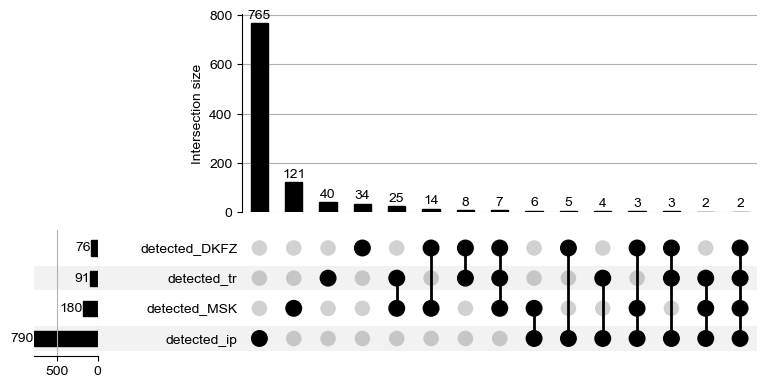

In [21]:
set_cols = ['detected_ip', 'detected_MSK',  'detected_tr','detected_DKFZ']
bool_df = df[set_cols].astype(bool)

# For inclusive intersections: for each possible combo of sets,
# count elements that are in ALL sets of that combo (regardless of other memberships)
index_tuples = []
counts = []

for r in range(1, len(set_cols) + 1):
    for combo in combinations(set_cols, r):
        # element must be True in every set in this combo
        mask = bool_df[list(combo)].all(axis=1)
        count = mask.sum()
        # MultiIndex tuple: True only for sets IN this combo
        index_tuples.append(tuple(col in combo for col in set_cols))
        counts.append(count)

index = pd.MultiIndex.from_tuples(index_tuples, names=set_cols)
data = pd.Series(counts, index=index)

print(data)  # sanity check before plotting

fig = plt.figure(figsize=(10, 5))
UpSet(data, subset_size='sum', sort_by='cardinality', show_counts=True).plot(fig)
plt.tight_layout()
plt.savefig('upset_plot.pdf',  dpi=300, bbox_inches='tight')
plt.show()